<h1>Workshop 5 - Data Analysis</h1>

<b>This work is about using Python to analyse your data.</b>

We'll start by getting Python speaking to your Arduino. We'll then move on to do some data analysis. 

We'll use [scipy](https://scipy.org/) for data analysis and [matplotlib](https://matplotlib.org/) for curve fitting.

There's also some extension material about more advanced plotting and good coding practice, but that's optional.

<h1>Python Activity 1 - Sending multiple commands to your MKR</h1>

<b>For this Activity, you'll need the Arduino code that you built in Workshop 5, Activity 1.</b> 

Alternatively, there's some Arduino pre-written code that you can use at the [Workshop 5 GitHub repo](https://github.com/joeforth/CHEM501_Workshop5).

Just as in most previous weeks, your task is to get some semi-familiar Python code talking to your MKR.

## Exercise 1
Take a look at the code below and do the following:

1. Search any lines of code that you don't understand on the internet - use Google, ChatGPT, or any tool you like to understand what's happening.

1. Get the code below working for *your* computer.

1. Just like with the Arduino exercise, modify your code so that your Arduino sends:
    - 10 readings at 1 reading per second.
    - 10 readings at 5 readings per second.
    - 100 readings at 100 readings per second.

1. Use the code above to save three .csv files: 
    - `data_10.csv` (containing 10 data points) 
    - `data_100.csv` (containing 100 data points) 
    - `data_1000.csv` (containing 1000 data points) 

Example output you'll get from the code if it runs successfully is posted below.

In [1]:
import serial
import serial.tools.list_ports
import pandas as pd
import numpy as np
import time

column_titles = ['time', 'temp', 'pressure', 'gas']
n_readings = 20
r_readings = 10

# Connect to the Nicla
ports = serial.tools.list_ports.comports()
for n in ports:
    # Print the names of the devices connected to the computer - your Nicla will be one of them.
    print(n.description)
    print(n.device)
    # You may be able to use the following lines to automatically set the Serial port:
    if 'Arduino' in n.description:
        dev = n.device

# You need to change the line below to the right Serial port for your Nicla:
dev = 'COM8'

# In general - baudrate=115200 and you shouldn't change it. You'll find tuning timeout can be useful for improving the quality of your data.
mkr = serial.Serial(port=dev, baudrate=115200, timeout=0.1)

# Clear the buffer for the Nicla serial port
mkr.flush()
mkr.reset_input_buffer()

# Send number and rate of sensor readings to the Nicla - this will tell the Nicla to start collecting data
mkr.write(bytes("{f0},{f1}".format(f0=n_readings,f1=r_readings), 'utf-8'))

# Create a numpy array to store the data
data_table = np.zeros((n_readings, len(column_titles)))
for n in range(n_readings):
    for readAttempt in range(100):
        data = mkr.readline()
        data = np.fromstring(data, sep=',')

        if len(data) == len(column_titles):
            break;
        print("Failed to read data index {} (attempt number {} out of 100). Trying again...".format(n, readAttempt+1))
        time.sleep(0.01)

    # Put the data in the nth row a numpy array
    data_table[n,:] = data

mkr.close()

# # Put the data in a DataFrame
data = pd.DataFrame(data_table, columns=column_titles)
data.to_csv('data_' + str(len(data)) + '.csv')

data

Arduino MKR WiFi 1010 (COM8)
COM8
Failed to read data index 0 (attempt number 1 out of 100). Trying again...
Failed to read data index 0 (attempt number 2 out of 100). Trying again...
Failed to read data index 0 (attempt number 3 out of 100). Trying again...
Failed to read data index 0 (attempt number 4 out of 100). Trying again...
Failed to read data index 0 (attempt number 5 out of 100). Trying again...
Failed to read data index 0 (attempt number 6 out of 100). Trying again...
Failed to read data index 0 (attempt number 7 out of 100). Trying again...
Failed to read data index 0 (attempt number 8 out of 100). Trying again...
Failed to read data index 0 (attempt number 9 out of 100). Trying again...
Failed to read data index 0 (attempt number 10 out of 100). Trying again...
Failed to read data index 0 (attempt number 11 out of 100). Trying again...
Failed to read data index 0 (attempt number 12 out of 100). Trying again...
Failed to read data index 1 (attempt number 1 out of 100). Tryi

,time,temp,pressure,gas
0,508.0,26.98,959.64,65235.0
1,718.0,26.98,959.64,65380.0
2,858.0,26.98,959.64,65380.0
3,1018.0,26.99,959.64,64996.0
4,1158.0,26.99,959.62,64853.0
5,1288.0,26.99,959.62,64853.0
6,1439.0,26.99,959.62,64996.0
7,1569.0,26.99,959.62,64996.0
8,1709.0,26.99,959.62,65332.0
9,1839.0,26.99,959.62,65332.0


<h1>Take a Break</h1>
We'll discuss the Week 5 Digital Discovery Paper.

<h1>Python Activity 2 - Revision of Simple Plotting</h1>



<h3>2.1 Data Filtering</h3>
Let's quickly review basic data tidying and plotting in <b>pandas</b> and <b>matplotlib</b> before doing some more complicated analysis.

Start by importing some useful modules:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
mpl.rcParams['axes.formatter.useoffset'] = False    # Remove annoying auto-offset

### 2.2 Summarising Data with `pandas`

First - we'll use `pandas` to load our file with 1000 data points and use the `describe()` function to take a quick look at our data:

In [4]:
data = pd.read_csv('./data_1000.csv', index_col=0)
data.describe()

,time,temp,pressure,gas
count,1000.000000,1000.000000,1000.00000,1000.00000
mean,69862.726000,23.544960,1020.47512,24869.24500
std,40094.549496,0.201492,0.02722,108.61805
min,509.000000,23.210000,1020.40000,24541.00000
25%,35181.500000,23.330000,1020.46000,24802.00000
50%,69822.000000,23.610000,1020.48000,24876.00000
75%,104547.500000,23.750000,1020.49000,24935.00000
max,139264.000000,23.780000,1020.53000,25205.00000


### 2.3 Data Filtering and Basic Plotting

Now - remove statistical outliers - in the example below, we remove data from the lower and highest percentile:

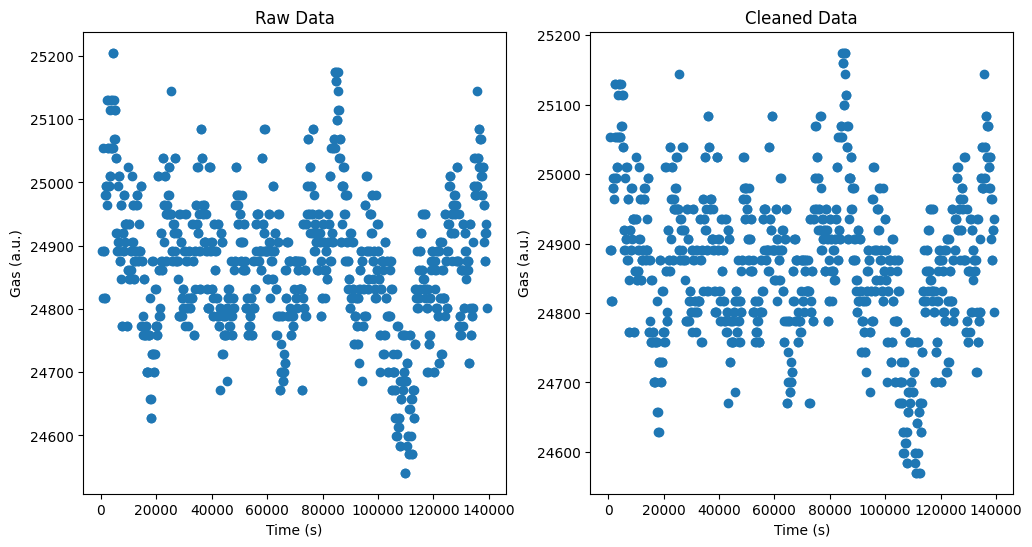

In [5]:
lower_bound = data['gas'].quantile(0.0001)
upper_bound = data['gas'].quantile(0.9999)

data_gas_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(121)
ax1.scatter(data['time'], data['gas'])
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Gas (a.u.)')
ax1.set_title('Raw Data')

ax2 = fig.add_subplot(122)
ax2.scatter(data_gas_clean['time'], data_gas_clean['gas'])
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Gas (a.u.)')
ax2.set_title('Cleaned Data')
plt.show()


## Exercise 2

Produce plots of data before and after cleaning from the other sensors that you're reading from (pressure and gas, if you're using the code given to you!) - save plots of the data from all three sensors.

<h1>Python Activity 3 - More Complex Plotting</h1>

Now let's do some proper data visualisation and analysis.

We'll look at histograms to investigate the statistical distribution of your data points. A [histogram](https://en.wikipedia.org/wiki/Histogram) is a type of graph that, rather than plotting one variable as a function of another, gives you information about how often particular values appear in your data set. 


<h3>3.1 - Histograms</h3>
Pick the noisiest data from either your gas, pressure, or tempreature sensor. In the following examples we'll use the gas sensor, but temperature and pressure may work equally well.

Let's start by visualising the noise in your data, after we've excluded outliers such as 0 values:

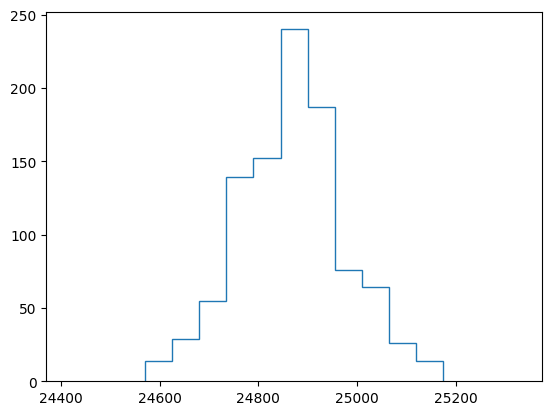

In [ ]:
data = pd.read_csv('./data_1000.csv', index_col=0)

lower_bound = data['gas'].quantile(0.001)
upper_bound = data['gas'].quantile(0.999)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]

counts, bins = np.histogram(data_clean['gas'], bins=11)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.stairs(counts, bins)
ax.set_xlim(bins[0]-200, bins[-1]+200)
plt.show()

## Exercise 3

First - modify the quantiles you're exluding so that you're only excluding outliers. You may find you don't need to exlude outliers at all (this was the case for the dataset that I took!)

Now - search the internet, stackoverflow, and ChatGPT to add the following features to your graphs:

1. Change the number of bars/bins in your histogram to suit your data - if you're really nailing it, you could use [Sturge's Rule](https://en.wikipedia.org/wiki/Sturges%27s_rule) to calculate how many bins there should be.
1. Title, x- and y-labels.
1. Modify the x-tick label font size so that the graph labels are clear.
1. Make the lines on histogram bars thicker.
1. Change the fill and border colours for the bars in your plot.
1. Save the plot when you're happy with it.
1. Bonus - run through this page - https://numpy.org/doc/stable/reference/generated/numpy.histogram.html - and find out how to normalise your histogram

<h3>3.2 - Curve Fitting</h3>

Now let's look at using a Python library called `scipy` to fit a curve to our data. Specifically, we'll use `curve_fit` to fit our data using the [Levenberg-Marquardt algorithm](https://en.wikipedia.org/wiki/Levenberg%E2%80%93Marquardt_algorithm). 

A Gaussian (or 'normal') distribution is defined by the following equation:

$$f(x; \sigma, \mu) = A \ \mathrm{exp} \left ( \frac{-(x-\mu)^2}{2\sigma^2} \right )$$

The code we use to fit this equation to our data is given below. 

Read through the comments, search the internet and use the print command to understand any functions that are unfamiliar to you:

25205.0 108.61805032247567 24869.245
[  212.9066475     99.77207061 24867.23984472]


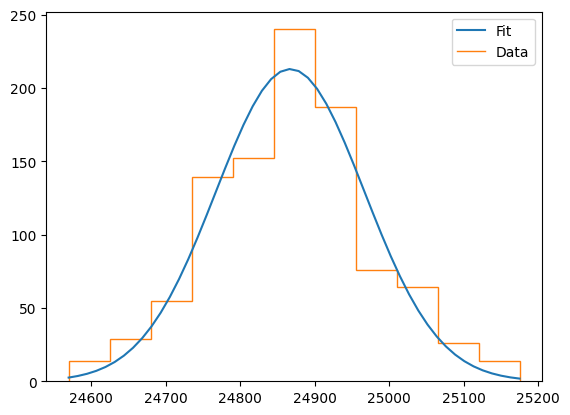

In [ ]:
from scipy.optimize import curve_fit

# Define the function we're fitting
def gaussian(x, a, sigma, mu):
    return a*np.exp((-1*(x - mu)**2)/(2*sigma**2))

# Calculate the mid-points of the histogram bins - so convert it to a scatter graph
bins_midpoint = (bins[:-1] + bins[1:]) / 2.

# We need to feed the fit algorithm initial guesses of the values in our function
a_guess, std_guess, mean_guess = 200, 200, 25000

# A cheat's way of finding the initial guesses for a Gaussian is in the line below:
# a_guess, std_guess, mean_guess = data['gas'].max(), data['gas'].std(), data['gas'].mean()

print(a_guess, std_guess, mean_guess)
fit_params = np.array([a_guess, std_guess, mean_guess])

# popt - values for the mean and standard deviation of our plot
# pcov - measures how good the fit is
# Read the module documentation for full details - https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html
popt, pcov = curve_fit(gaussian, bins_midpoint, counts, p0=fit_params)
print(popt)

# Plot the data and the fit
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(np.linspace(bins[0], bins[-1]), gaussian(np.linspace(bins[0], bins[-1]), popt[0], popt[1], popt[2]), label='Fit')
ax.stairs(counts, bins, label='Data')
plt.legend()
plt.show()


## Exercise 4 - Getting Curve Fitting to Work

1. Get the above code working for your data so you can fit a normal distribution to your data - you'll find you'll have to do things like change the initial guesses you feed `curve_fit()` or that it may not even 

1. Read the documentation for `curve_fit()` [here](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) to learn what `popt` and `pcov` are.

1. Hence, figure out the mean and standard deviation of the Gaussian that you're fitting. How do they differ from the true mean and standard deviation of your data that you can calculate directly (e.g., using pandas `describe()` function, like earlier)?

Congratulations - you've just done your first bit of machine learning!


## Exercise 5 - Fitting your data better

It may be that your data isn't well-fitted by a Gaussian distribution - there are lots of reasons that this might happen, but there are 2 key reasons that you're likely to encounter here:

<b>1. Multi-Modal Data</b>

If something <i>changes</i> during the measurement (e.g., the room warms up or a door opens) your system will end up measuring multiple different values, each with some noise associated with it. One way of modelling this is to use two (or more) Gaussians - where the mean of each Gaussian corresponds to the value of each measurement, and the standard deviation corresponds to the noise in each measurement.

<b>2. Fat-Tailed Data</b>

To keep things simple (as well as [more rigorous reasons](https://en.wikipedia.org/wiki/Central_limit_theorem)), we tend to <i>assume</i> that our measurements of a single data point are Gaussian. Sometimes, however, that's not the case - such as in system where a Gaussian distribution tends to underestimate how often "rare" events (i.e. outliers) happen. 

These datasets can instead be better fit by a Lorentzian (sometimes called a Cauchy Distribution):

$$f(x; x_0, \gamma) = \frac{}{} \left[ \frac{\gamma}{(x-x_0)^2 + \gamma^2} \right ]$$

Where $x_0$ and $\gamma$ are the peak location and half-width of your function, respectively.

### And now for the actual exercise...
Find out whether each of your data sets (`data_10.csv`, `data_100.csv`, and `data_1000.csv`) are best fit by a Gaussian, multiple Gaussians, or a Lorentzian. Create plots showing fits to your datasets. 

If you want to push yourself, you could try and be quantitative about deciding whether a fit is good. To do this, you'll need to explore the `curve_fit` module [documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html) to understand what `pcov` is. You could also explore using other metrics for ['goodness of fit'](https://docs.scipy.org/doc/scipy-1.16.1/reference/generated/scipy.stats.goodness_of_fit.html).

<h1>End of the Workshop</h1>
Your homework is to start planning your projects. Everything below is bonus content!

<h1>Extended Material</h1>
Sometimes you'll want to put multiple plots in a single figure. We'll start by referring to them one-by-one (painful!). You homework will be to explore a cleverer way of editing them.

We'll use matplotlib's subplots command - https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

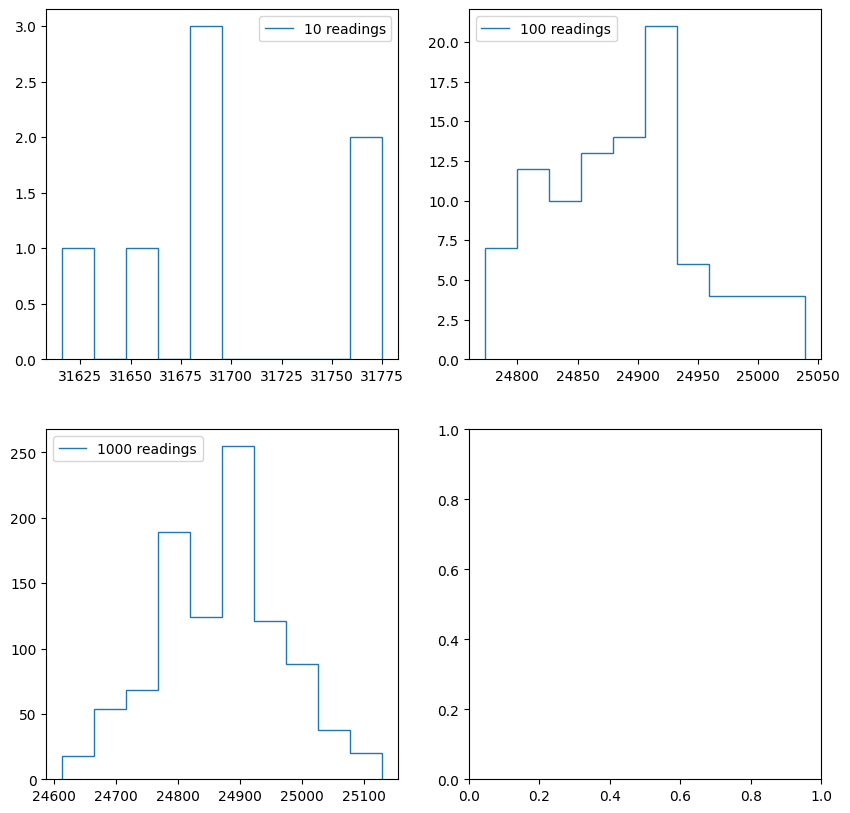

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(10,10))

data = pd.read_csv('./data_10.csv', index_col=0)
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[0,0].stairs(counts, bins, label='10 readings')
axs[0,0].legend()

data = pd.read_csv('./data_100.csv', index_col=0)
counts, bins = np.histogram(data['gas'])
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[0,1].stairs(counts, bins, label='100 readings')
axs[0,1].legend()

data = pd.read_csv('./data_1000.csv', index_col=0)
lower_bound = data['gas'].quantile(0.01)
upper_bound = data['gas'].quantile(0.99)
data_clean = data[(data['gas'] > lower_bound) & (data['gas'] < upper_bound)]
counts, bins = np.histogram(data_clean['gas'])
axs[1,0].stairs(counts, bins, label='1000 readings')
axs[1,0].legend()

## Exercise 6

1. Add lines of best fit to all 3 plots.

1. Figure out how to remove the empty fourth plot.

## Extended Material Part 2
See that fourth graph? Use it to plot all three histograms on the same graph.

You'll want to normalise them and offset them by a constant value so you can see all 3 graphs in the same plot. 

<b>What does normalise mean?</b>

It means that, instead of plotting the total number of measurements, you instead plot the histograms so either the maximum value of the plot is 1, or the total area under the histogram is 1 (this is called a probability density function in the link below). You can learn about how to normalise histograms here:
https://numpy.org/devdocs/reference/generated/numpy.histogram.html

<h1>Making Your Code DRY</h1>
We run a lot of the same code over and over again in that last exercise, don't we? This is bad - it makes our code hard to read and lots of work to edit. 

Let's look at some ways to make the code [DRY](https://en.wikipedia.org/wiki/Don%27t_repeat_yourself) (<b>D</b>on't <b>R</b>epeat <b>Y</b>ourself)


<h3>4.1 - Figuring out what files are in a directory</h3>
Rather than specifying what files to run our analysis on, let's automate finding the files based on a shared trait that is unique to them - in this case, the file format.

In [13]:
# First - let's put together a list of files 
import os
files_all = os.listdir('./')    # Files in the directory that this code is in
files = [file for file in files_all if '.csv' in file]    # Remove files from the list that aren't .csv files
print(files)

['data_10.csv', 'data_100.csv', 'data_1000.csv', 'data_20.csv']


<h3>4.2 - Using Loops to Set Plot Properties</h3>
Instead of referring to our plots one-by-one, we can use a for loop to refer to them in a single line of code. In many cases, we don't even have to enter the data manually. Let's look at an example of how to do this below:

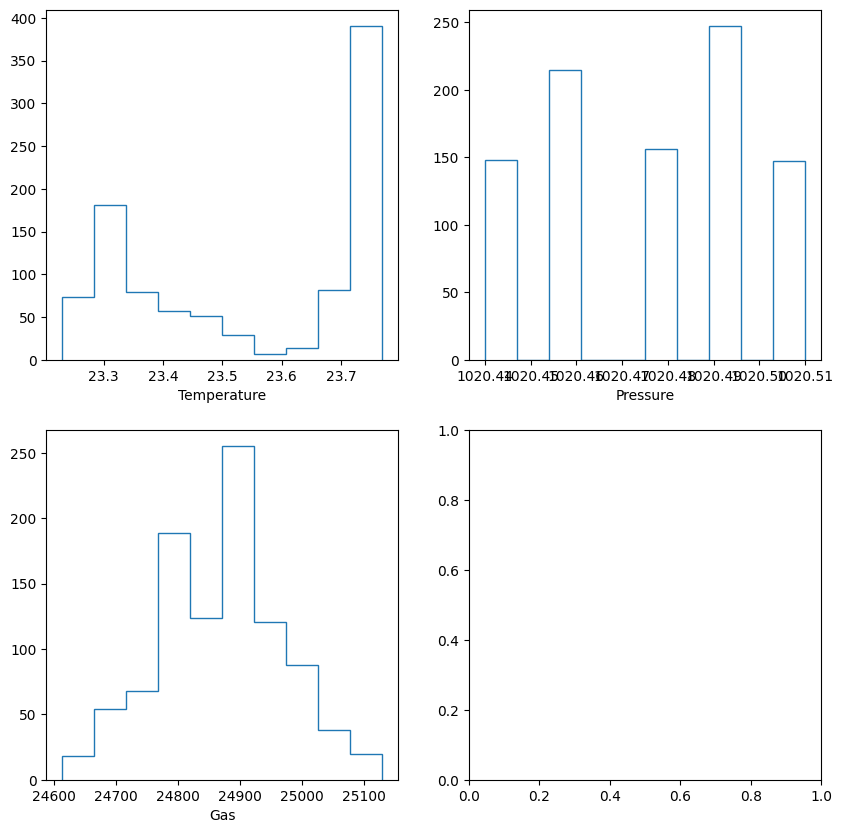

In [14]:
def hist_calc(data_in, var_in, lq_in=0.01, uq_in=0.99):
    # Add a comment to say what this function does
    counts_out, bins_out = np.histogram(data_in[var_in])
    lower_bound = data_in[var_in].quantile(lq_in)
    upper_bound = data_in[var_in].quantile(uq_in)
    data_clean = data_in[(data[var_in] > lower_bound) & (data[var_in] < upper_bound)]
    counts_out, bins_out = np.histogram(data_clean[var_in])
    return counts_out, bins_out

data = pd.read_csv('data_1000.csv', index_col=0)
column_titles = data.columns.tolist()
column_titles = column_titles[1:]
n_vars = len(column_titles)
var_names = ['Temperature', 'Pressure', 'Gas']

nrows = int(np.ceil(np.sqrt(n_vars)))
ncols = int(n_vars // nrows + 1)
fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))

for n, sensor in enumerate(column_titles):
    i = n // ncols
    j = n % ncols
    counts, bins = hist_calc(data, column_titles[n])
    axs[i,j].stairs(counts, bins)
    axs[i,j].set_xlabel(var_names[n])

# plt.show()


## Final Bonus Exercise

1. Run through the above code adding comments saying what each line does - you'll want to a combination of google searches and the print command.

1. Figure out how to remove the pesky empty final graph. I thought [this was a really nice guide](https://engineeringfordatascience.com/posts/matplotlib_subplots/) on some nice approaches to this.

1. Use your for loop to modify the appearance of your plots, focus on clear presentation and aesthetic appeal.

1. Use a second 'for' loop to produce plots for all 3 of the data files you saved earlier (the ones containing 10, 100, and 1000 data points).

<b>End of Workshop</b>
